# PowerPulse — Optimized Training Pipeline (Google Colab) (BDG2 · LSTM + MLP + Transformer + Ensemble)
**Task:** use the previous **168 h** to forecast the next **24 h** of building electricity demand, then flag likely peak hours.

**Dataset: Building Data Genome Project 2 (BDG2)** — Miller et al., *Scientific Data* 7, 368 (2020), https://doi.org/10.1038/s41597-020-00712-x
Open, whole-building **hourly electricity for 2 full years (2016–2017)** from 1,636 non-residential buildings, with site weather and building metadata. Same lineage as the ASHRAE competition data, but *cleaned*, **2 years instead of 1**, no competition login/rules, and a download that is a few tens of MB instead of ~0.5 GB.

**What changed vs the previous notebook**
| # | Optimization | Why it helps |
|---|---|---|
| 1 | BDG2 *cleaned* electricity, 2 years | double the history, seasonal coverage in train |
| 2 | Building picked automatically from **train-period** data quality + regularity | removes dead/flat/gappy meters; no test peeking |
| 3 | Window-level normalisation (`load_rel`) | level-invariant, robust to seasonal drift |
| 4 | Known **future calendar features** fed to the model | hour/day-of-week of the hours being forecast are known in advance |
| 5 | Skip connection from the previous-day shape | models start from seasonal-naive and learn corrections |
| 6 | Huber loss, gradient clipping, LR scheduling, random-search tuning on **validation** | robust training, honest tuning |
| 7 | Mean **Ensemble** of LSTM + MLP + Transformer | usually the most accurate and stable |
| 8 | Model **selected on validation**, reported on untouched test | no selection leakage |
| 9 | Extra metrics: CV(RMSE), NMBE, peak precision/recall/F1, 80 % prediction interval | building-energy-standard + early-warning-specific evaluation |
| 10 | Shared `powerpulse_pipeline.py` + JSON config exported | backend rebuilds *identical* inputs (no train/serve skew) |
| 11 | Round-trip test: reload saved models and reproduce predictions | proves artifacts are backend-ready |

**Colab setup (2 min):** 1) Runtime → Change runtime type → **T4 GPU**. 2) Put the BDG2 dataset **ZIP** in `MyDrive/PowerPulse/` (Kaggle: search *Building Data Genome Project 2*; it must contain `electricity_cleaned.csv`, `weather.csv`, `metadata.csv`). 3) Run all cells. Outputs are written straight to `MyDrive/PowerPulse/artifacts/`, zipped to `MyDrive/PowerPulse/powerpulse_artifacts.zip`, and downloaded to your computer.

*Full run is roughly 30–60 min on a T4 (set `FAST_MODE = True` in the config cell for a ~5-min smoke test).*

## 1) Environment & paths

In [10]:
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

# ---- Put the BDG2 dataset ZIP (e.g. the Kaggle download) in MyDrive/PowerPulse/ ----
BASE_DRIVE     = Path("/content/drive/MyDrive/PowerPulse")
BASE_DRIVE.mkdir(parents=True, exist_ok=True)
WORK           = Path("/content/powerpulse_work")            # fast local scratch space
RAW_DIR        = WORK / "raw"
CODE_DIR       = WORK / "code"
ARTIFACTS_PATH = BASE_DRIVE / "artifacts"                    # every output is written STRAIGHT to Drive
MODELS_PATH    = ARTIFACTS_PATH / "models"
CONFIG_PATH    = ARTIFACTS_PATH / "config"
DATA_OUT       = ARTIFACTS_PATH / "data"
FIG_PATH       = ARTIFACTS_PATH / "figures"
for p in (RAW_DIR, CODE_DIR, ARTIFACTS_PATH, MODELS_PATH, CONFIG_PATH, DATA_OUT, FIG_PATH):
    p.mkdir(parents=True, exist_ok=True)

ZIP_DIR           = BASE_DRIVE
DATA_SEARCH_ROOTS = [BASE_DRIVE]                             # also finds already-unzipped CSVs

def fetch_missing_files(found):
    raise FileNotFoundError(
        "BDG2 files not found. Upload the dataset ZIP to MyDrive/PowerPulse/ "
        "(it must contain electricity_cleaned.csv, weather.csv and metadata.csv) and re-run. "
        f"Currently found: {list(found)}; zips in folder: {[z.name for z in BASE_DRIVE.glob('*.zip')]}")

print("Zips in", BASE_DRIVE, "->", [z.name for z in BASE_DRIVE.glob("*.zip")])
print("Outputs will be saved to:", ARTIFACTS_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Zips in /content/drive/MyDrive/PowerPulse -> ['ASHRAE - Great Energy Predictor III.zip', 'powerpulse_artifacts.zip', 'BDG2.zip']
Outputs will be saved to: /content/drive/MyDrive/PowerPulse/artifacts


## 2) Configuration

In [11]:
import json, math, random, re, sys, time, warnings, importlib, shutil, zipfile, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ---------------- Experiment configuration ----------------
SEED          = 42
INPUT_HOURS   = 168          # history window (7 days)
HORIZON       = 24           # forecast horizon (next 24 h)
BUILDING_ID   = None         # None = auto-select; or e.g. "Panther_office_Hannah"
MIN_COVERAGE  = 0.97         # min fraction of non-missing hours for a candidate building
MIN_MEAN_KWH  = 10.0         # ignore tiny meters
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15        # chronological split; test = remaining 15 %
PEAK_QUANTILE = 0.90         # peak threshold = 90th percentile of TRAIN-period load

FAST_MODE     = False        # True = quick smoke run (a few epochs, 2 tuning trials)
N_TRIALS      = 2 if FAST_MODE else 6    # random-search trials per model
TUNE_EPOCHS   = 2 if FAST_MODE else 12
FINAL_EPOCHS  = 3 if FAST_MODE else 60
BATCH         = 128

WEATHER_MAP = {"airtemperature": "air_temperature", "dewtemperature": "dew_temperature",
               "windspeed": "wind_speed", "sealvlpressure": "sea_level_pressure",
               "cloudcoverage": "cloud_coverage", "precipdepth1hr": "precip_depth_1_hr"}

random.seed(SEED); np.random.seed(SEED)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | Keras 3.13.2 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3) Shared feature pipeline (also shipped to the backend)
All feature engineering lives in one module so that **training and serving use the same code**. It is written to `artifacts/` and imported from there.

In [12]:
CODE_DIR.mkdir(parents=True, exist_ok=True)
PIPELINE_SRC = r'''"""PowerPulse shared preprocessing pipeline.

Used by the training notebooks AND by the FastAPI backend so that training and
serving build *identical* model inputs (no train/serve skew).

Model inputs (all built from PAST observations + known calendar features only):
    hist : (n, INPUT_HOURS, F)  past window: [load_rel, weather..., calendar..., window_pos]
    fut  : (n, HORIZON, 7)      calendar features of the hours to be forecast (known in advance)
    stat : (n, 1)               standardised mean log-load level of the past window
    base : (n, HORIZON)         previous-day load_rel (skip connection = seasonal-naive start point)
Target:
    y    : (n, HORIZON)         (log1p(load) - window_mean) / scale

load_rel = (log1p(kWh) - mean(log1p(kWh) over the window)) / scale
-> level-invariant, which makes the models robust to load drift between seasons.
"""
import numpy as np
import pandas as pd

CAL_COLS = ["hour_sin", "hour_cos", "dow_sin", "dow_cos",
            "month_sin", "month_cos", "is_weekend"]
MODEL_INPUT_KEYS = ("hist", "fut", "stat", "base")


# ----------------------------------------------------------------------------- features
def calendar_features(index):
    idx = pd.DatetimeIndex(index)
    return pd.DataFrame({
        "hour_sin": np.sin(2 * np.pi * idx.hour / 24),
        "hour_cos": np.cos(2 * np.pi * idx.hour / 24),
        "dow_sin": np.sin(2 * np.pi * idx.dayofweek / 7),
        "dow_cos": np.cos(2 * np.pi * idx.dayofweek / 7),
        "month_sin": np.sin(2 * np.pi * (idx.month - 1) / 12),
        "month_cos": np.cos(2 * np.pi * (idx.month - 1) / 12),
        "is_weekend": (idx.dayofweek >= 5).astype(float),
    }, index=idx)


def fill_short_gaps(s, max_gap):
    """Linearly interpolate ONLY interior gaps of <= max_gap hours. Longer gaps stay NaN."""
    s = s.replace([np.inf, -np.inf], np.nan)
    isna = s.isna()
    run_id = (~isna).cumsum()
    run_len = isna.groupby(run_id).transform("sum")
    interp = s.interpolate(method="time", limit_area="inside")
    out = s.copy()
    m = isna & (run_len <= max_gap)
    out[m] = interp[m]
    return out


def make_frame(load, weather=None, weather_cols=(), max_gap_load=6, max_gap_weather=24):
    """Complete hourly grid with cleaned load (kWh), log load, weather and calendar columns."""
    load = pd.Series(load).astype(float)
    load = load[~load.index.duplicated(keep="last")].sort_index()
    idx = pd.date_range(load.index.min(), load.index.max(), freq="h")
    load = load.reindex(idx)
    load = load.where(load >= 0)                       # negative readings -> missing
    load = fill_short_gaps(load, max_gap_load)
    frame = pd.DataFrame({"load_kwh": load}, index=idx)
    frame["log_load"] = np.log1p(frame["load_kwh"])
    for c in weather_cols:
        if weather is not None and c in weather.columns:
            w = weather[c].astype(float)
            w = w[~w.index.duplicated(keep="last")].sort_index()
            w = w.resample("h").mean().reindex(idx)
            w = fill_short_gaps(w, max_gap_weather).ffill(limit=max_gap_weather).bfill(limit=max_gap_weather)
        else:
            w = np.nan
        frame[c] = w
    frame = frame.join(calendar_features(idx))
    frame.index.name = "timestamp"
    return frame


def feature_names(cfg):
    return ["load_rel"] + list(cfg["weather_cols"]) + CAL_COLS + ["window_pos"]


# ----------------------------------------------------------------------------- normaliser
def fit_normalizer(frame, train_end, cfg):
    """Statistics from TRAIN rows only (positions < train_end) -> no leakage."""
    H, wc = cfg["input_hours"], list(cfg["weather_cols"])
    tr = frame.iloc[:train_end]
    L = frame["log_load"]
    ref_all = L.rolling(H, min_periods=H).mean().shift(1)    # window mean aligned at forecast origin
    dev = (L - ref_all).iloc[:train_end].dropna()
    ref_tr = ref_all.iloc[:train_end].dropna()
    wstd = {c: float(tr[c].std()) if tr[c].notna().sum() > 1 else 1.0 for c in wc}
    return {
        "weather_mean": {c: float(tr[c].mean()) if tr[c].notna().any() else 0.0 for c in wc},
        "weather_std": {c: (v if np.isfinite(v) and v > 1e-9 else 1.0) for c, v in wstd.items()},
        "scale": float(dev.std()),
        "ref_mean": float(ref_tr.mean()),
        "ref_std": float(ref_tr.std()),
    }


# ----------------------------------------------------------------------------- windows
def build_inputs(frame, origins, cfg, norm, with_target=True):
    """Build model inputs for forecast origins (integer positions into `frame`).

    A forecast at origin t uses hours [t-H, t) as history and predicts hours [t, t+T).
    origin == len(frame) is a genuine forecast beyond the last observation.
    Windows with missing history (or missing target when with_target) are dropped;
    the surviving origins are returned in out["origins"].
    """
    H, T, wc = cfg["input_hours"], cfg["horizon"], list(cfg["weather_cols"])
    origins = np.asarray(origins, dtype=int)
    N = len(frame)
    ext_idx = frame.index.append(
        pd.date_range(frame.index[-1] + pd.Timedelta(hours=1), periods=T, freq="h"))
    cal = calendar_features(ext_idx)[CAL_COLS].to_numpy(np.float32)
    L = np.concatenate([frame["log_load"].to_numpy(np.float64), np.full(T, np.nan)])
    W = np.zeros((N + T, len(wc)), np.float32)
    for j, c in enumerate(wc):
        z = (frame[c].to_numpy(np.float64) - norm["weather_mean"][c]) / norm["weather_std"][c]
        W[:N, j] = np.nan_to_num(z, nan=0.0)

    ok = (origins >= H) & (origins <= N)
    o = np.where(ok, origins, H)                       # safe indices for invalid origins
    hidx = o[:, None] + np.arange(-H, 0)[None, :]
    fidx = o[:, None] + np.arange(T)[None, :]
    Lh = L[hidx]
    ok &= ~np.isnan(Lh).any(axis=1)
    if with_target:
        Ly = L[fidx]
        ok &= ~np.isnan(Ly).any(axis=1)
    keep = np.where(ok)[0]
    hidx, fidx, Lh = hidx[keep], fidx[keep], Lh[keep]

    ref = Lh.mean(axis=1)
    rel = np.clip((Lh - ref[:, None]) / norm["scale"], -10, 10).astype(np.float32)
    pos = np.broadcast_to(np.linspace(-1, 0, H, dtype=np.float32), (len(keep), H))
    hist = np.concatenate([rel[..., None], W[hidx], cal[hidx], pos[..., None]], axis=2)
    out = {
        "origins": origins[keep],
        "hist": hist.astype(np.float32),
        "fut": cal[fidx],
        "stat": ((ref - norm["ref_mean"]) / norm["ref_std"])[:, None].astype(np.float32),
        "base": rel[:, -T:].astype(np.float32),
        "ref": ref,
    }
    if with_target:
        out["y"] = np.clip((Ly[keep] - ref[:, None]) / norm["scale"], -10, 10).astype(np.float32)
    return out


def model_inputs(d):
    return {k: d[k] for k in MODEL_INPUT_KEYS}


def denormalize(pred_norm, ref, norm):
    """Model output -> kWh."""
    log_pred = np.clip(np.asarray(pred_norm) * norm["scale"] + np.asarray(ref)[:, None], 0.0, 25.0)
    return np.expm1(log_pred)


def actual_kwh(frame, origins, cfg):
    load = frame["load_kwh"].to_numpy(np.float64)
    return load[np.asarray(origins)[:, None] + np.arange(cfg["horizon"])[None, :]]


def naive_baselines(frame, origins, cfg):
    """Previous-day and previous-week forecasts in kWh."""
    load = frame["load_kwh"].to_numpy(np.float64)
    o = np.asarray(origins)[:, None]
    ar = np.arange(cfg["horizon"])[None, :]
    return {"day": load[o - 24 + ar], "week": load[o - 168 + ar]}
'''
(CODE_DIR / 'powerpulse_pipeline.py').write_text(PIPELINE_SRC)
sys.path.insert(0, str(CODE_DIR))
import powerpulse_pipeline as pp
importlib.reload(pp)

def savefig(name):
    plt.savefig(FIG_PATH / name, dpi=150, bbox_inches='tight')
    plt.show()

print('Pipeline module loaded:', pp.__file__)

Pipeline module loaded: /content/powerpulse_work/code/powerpulse_pipeline.py


## 4) Locate & load the BDG2 files

In [13]:
NEEDED = {"electricity": ["electricity_cleaned.csv", "electricity.csv"],
          "weather":     ["weather.csv"],
          "metadata":    ["metadata.csv"]}
WANTED_NAMES = {n for v in NEEDED.values() for n in v}

def _find(root, names):
    root = Path(root)
    if not root.exists():
        return None
    for n in names:
        hits = sorted(p for p in root.rglob(n) if ARTIFACTS_PATH not in p.parents)
        if hits:
            return hits[0]
    return None

def locate_all(roots):
    found = {}
    for key, names in NEEDED.items():
        for r in roots:
            p = _find(r, names)
            if p:
                found[key] = p
                break
    return found

def extract_zips(zip_dir, dest):
    for z in sorted(Path(zip_dir).glob("*.zip")):
        print("Scanning zip:", z.name)
        with zipfile.ZipFile(z) as zf:
            for m in zf.namelist():
                if not m.endswith("/") and Path(m).name in WANTED_NAMES:
                    zf.extract(m, Path(dest) / z.stem)

files = locate_all(DATA_SEARCH_ROOTS)
if len(files) < 3:
    extract_zips(ZIP_DIR, RAW_DIR)
    files = locate_all(DATA_SEARCH_ROOTS + [RAW_DIR])
if len(files) < 3:
    files = fetch_missing_files(files)           # Jupyter: optional download; Colab: raises a clear error

for k, p in files.items():
    size = p.stat().st_size
    print(f"{k:12s} {p}  ({size/1e6:.1f} MB)")
    assert size > 2048, (f"{p.name} is only {size} bytes - it is a Git-LFS pointer, not data. "
                         "'Download ZIP' on GitHub does NOT include LFS files. Use the Kaggle dataset zip "
                         "(search 'Building Data Genome Project 2') or the download cell in the Jupyter notebook.")

def canon(c): return re.sub(r"[^a-z0-9]", "", str(c).lower())

elec = pd.read_csv(files["electricity"], index_col=0, parse_dates=True).sort_index()
elec = elec[~elec.index.duplicated(keep="last")]
elec.index.name = "timestamp"
print("Electricity:", elec.shape, "|", elec.index.min(), "->", elec.index.max())

meta = pd.read_csv(files["metadata"]); meta.columns = [canon(c) for c in meta.columns]
meta = meta.rename(columns={"buildingid": "building_id", "siteid": "site_id"}).set_index("building_id")
weather_raw = pd.read_csv(files["weather"]); weather_raw.columns = [canon(c) for c in weather_raw.columns]
weather_raw = weather_raw.rename(columns={**WEATHER_MAP, "siteid": "site_id"})
weather_raw["timestamp"] = pd.to_datetime(weather_raw["timestamp"])
print("Metadata:", meta.shape, "| Weather:", weather_raw.shape, "| sites:", weather_raw["site_id"].nunique())
display(meta.head(3))

Scanning zip: ASHRAE - Great Energy Predictor III.zip
Scanning zip: BDG2.zip
Scanning zip: powerpulse_artifacts.zip
electricity  /content/powerpulse_work/raw/BDG2/electricity_cleaned.csv  (175.0 MB)
weather      /content/powerpulse_work/raw/BDG2/weather.csv  (19.5 MB)
metadata     /content/powerpulse_work/raw/BDG2/metadata.csv  (0.3 MB)
Electricity: (17544, 1578) | 2016-01-01 00:00:00 -> 2017-12-31 23:00:00
Metadata: (1636, 31) | Weather: (331166, 10) | sites: 19


,site_id,buildingidkaggle,siteidkaggle,primaryspaceusage,subprimaryspaceusage,sqm,sqft,lat,lng,timezone,...,yearbuilt,dateopened,numberoffloors,occupants,energystarscore,eui,siteeui,sourceeui,leedlevel,rating
building_id,,,,,,,,,,,,,,,,,,,,,
Panther_lodging_Dean,Panther,NaN,0.0,Lodging/residential,Residence Hall,508.8,5477.0,28.517689,-81.379039,US/Eastern,...,1989.0,NaN,NaN,NaN,NaN,271,NaN,NaN,NaN,NaN
Panther_lodging_Shelia,Panther,NaN,0.0,Lodging/residential,Residence Hall,929.0,10000.0,28.517689,-81.379039,US/Eastern,...,1992.0,NaN,NaN,NaN,NaN,62,NaN,NaN,NaN,NaN
Panther_lodging_Ricky,Panther,NaN,0.0,Lodging/residential,Residence Hall,483.1,5200.0,28.517689,-81.379039,US/Eastern,...,2016.0,NaN,NaN,NaN,NaN,534,NaN,NaN,NaN,NaN


## 5) Pick the target building (using TRAIN-period data only)
Candidates must have near-complete data (including the most recent week), almost no zero readings, a real daily/weekly shape (not a flat line), and a weather feed. They are ranked by the average of the 24 h and 168 h autocorrelation **computed on the training period only**, so the test period never influences the choice.

> ⚠️ Because the building is chosen for regularity, the reported accuracy describes *a well-instrumented building* — say so in the presentation. Set `BUILDING_ID` manually to evaluate any other building.

In [14]:
def site_of(b):
    if b in meta.index and "site_id" in meta.columns and pd.notna(meta.loc[b, "site_id"]):
        return str(meta.loc[b, "site_id"])
    return str(b).split("_")[0]

weather_cov = (weather_raw.groupby("site_id")["air_temperature"].apply(lambda s: s.notna().mean())
               if "air_temperature" in weather_raw.columns else pd.Series(dtype=float))
n_rows = len(elec); tr_end = int(n_rows * TRAIN_FRAC)

cands = []
for b in elec.columns:
    s = elec[b]
    if s.notna().mean() < MIN_COVERAGE or s.iloc[:tr_end].notna().mean() < MIN_COVERAGE: continue
    if s.iloc[-INPUT_HOURS:].notna().mean() < 0.95: continue          # needs recent data for live forecasts
    if (s.fillna(0) <= 0).mean() > 0.02: continue                      # dead meter / zero runs
    if weather_cov.get(site_of(b), 0) < 0.90: continue
    tr = s.iloc[:tr_end]; mu = tr.mean()
    if not mu >= MIN_MEAN_KWH: continue
    if tr.std() / mu < 0.15: continue                                  # flat load = nothing to forecast
    if (tr.quantile(.9) - tr.quantile(.1)) / mu < 0.30: continue
    lg = np.log1p(tr.clip(lower=0)).interpolate(limit_area="inside")
    a24, a168 = lg.autocorr(24), lg.autocorr(168)
    cands.append({"building_id": b, "site": site_of(b),
                  "primary_use": meta.loc[b, "primaryspaceusage"] if b in meta.index and "primaryspaceusage" in meta.columns else None,
                  "mean_kwh": round(mu, 1), "acf24": round(a24, 3), "acf168": round(a168, 3),
                  "score": round((a24 + a168) / 2, 3)})
cand_df = pd.DataFrame(cands).sort_values("score", ascending=False).reset_index(drop=True)
print(f"{len(cand_df)} eligible buildings out of {elec.shape[1]}")
display(cand_df.head(10))

if BUILDING_ID is None:
    assert len(cand_df), "No eligible building - relax MIN_COVERAGE / MIN_MEAN_KWH"
    BUILDING_ID = cand_df.loc[0, "building_id"]
assert BUILDING_ID in elec.columns, f"{BUILDING_ID} not in electricity file"
SITE_ID = site_of(BUILDING_ID)
building_info = meta.loc[BUILDING_ID].to_dict() if BUILDING_ID in meta.index else {}
print("\nSelected:", BUILDING_ID, "| site:", SITE_ID, "| use:", building_info.get("primaryspaceusage"),
      "| sqft:", building_info.get("sqft"))

720 eligible buildings out of 1578


,building_id,site,primary_use,mean_kwh,acf24,acf168,score
0,Hog_office_Rolando,Hog,Office,259.8,0.992,0.969,0.981
1,Hog_office_Gustavo,Hog,Office,438.8,0.987,0.966,0.976
2,Peacock_assembly_Socorro,Peacock,Entertainment/public assembly,15.2,0.982,0.959,0.970
3,Robin_education_Karyl,Robin,Education,47.0,0.989,0.941,0.965
4,Robin_office_Lindsay,Robin,Office,39.9,0.986,0.937,0.961
5,Rat_assembly_Pam,Rat,Entertainment/public assembly,10.7,0.985,0.931,0.958
6,Hog_warehouse_Porsha,Hog,Warehouse/storage,11.7,0.972,0.942,0.957
7,Rat_health_Tanya,Rat,Healthcare,48.3,0.972,0.935,0.954
8,Bear_education_Lila,Bear,Education,216.8,0.926,0.977,0.952
9,Rat_assembly_Michel,Rat,Entertainment/public assembly,13.6,0.976,0.922,0.949



Selected: Hog_office_Rolando | site: Hog | use: Office | sqft: 194111.0


## 6) Hourly frame, data quality, chronological split

Weather features used: ['air_temperature', 'dew_temperature', 'wind_speed', 'sea_level_pressure', 'precip_depth_1_hr']
Frame: (17544, 14) | features per timestep: 14
Train: 2016-01-01 00:00:00 -> 2017-05-26 15:00:00
Val:   2017-05-26 16:00:00 -> 2017-09-13 07:00:00
Test:  2017-09-13 08:00:00 -> 2017-12-31 23:00:00
{
  "missing_hours_raw": 1,
  "missing_pct_raw": 0.006,
  "gap_runs_remaining": 0,
  "latest_observation": "2017-12-31 23:00:00"
}


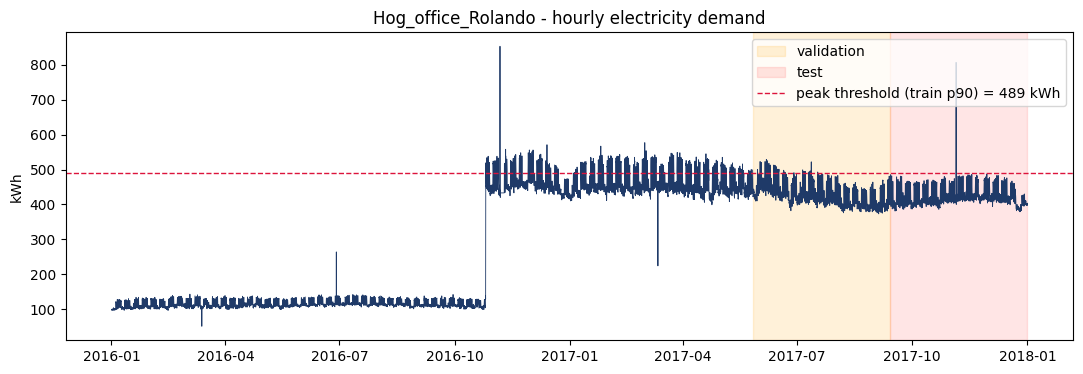

In [15]:
site_w = weather_raw[weather_raw["site_id"].astype(str) == SITE_ID].set_index("timestamp").sort_index()
WEATHER_USE = [c for c in WEATHER_MAP.values() if c in site_w.columns and site_w[c].notna().mean() >= 0.80]
print("Weather features used:", WEATHER_USE)

raw_series = elec[BUILDING_ID]
frame = pp.make_frame(raw_series, site_w, WEATHER_USE)
N = len(frame)
train_end, val_end = int(N * TRAIN_FRAC), int(N * (TRAIN_FRAC + VAL_FRAC))

CFG = {"input_hours": INPUT_HOURS, "horizon": HORIZON, "weather_cols": WEATHER_USE}
NORM = pp.fit_normalizer(frame, train_end, CFG)        # statistics from TRAIN rows only
FEATURES = pp.feature_names(CFG)
print("Frame:", frame.shape, "| features per timestep:", len(FEATURES))
print("Train:", frame.index[0], "->", frame.index[train_end - 1])
print("Val:  ", frame.index[train_end], "->", frame.index[val_end - 1])
print("Test: ", frame.index[val_end], "->", frame.index[-1])

missing_raw = int(raw_series.reindex(frame.index).isna().sum())
missing_after = int(frame["load_kwh"].isna().sum())
gap_runs = (frame["load_kwh"].isna().astype(int).diff().fillna(0) == 1).sum()
data_quality = {
    "dataset": "Building Data Genome Project 2 (BDG2) - cleaned electricity, hourly",
    "dataset_url": "https://github.com/buds-lab/building-data-genome-project-2",
    "citation": "Miller et al., Scientific Data 7, 368 (2020), doi:10.1038/s41597-020-00712-x",
    "building_id": BUILDING_ID, "site_id": SITE_ID,
    "primary_use": str(building_info.get("primaryspaceusage")),
    "square_feet": (int(building_info["sqft"]) if pd.notna(building_info.get("sqft", np.nan)) else None),
    "rows_hourly_grid": int(N),
    "date_range": [str(frame.index.min()), str(frame.index.max())],
    "latest_observation": str(frame["load_kwh"].last_valid_index()),
    "missing_hours_raw": missing_raw, "missing_hours_after_short_gap_fill": missing_after,
    "missing_pct_raw": round(100 * missing_raw / N, 3),
    "gap_runs_remaining": int(gap_runs),
    "weather_features": WEATHER_USE,
    "weather_missing_pct": {c: round(100 * float(frame[c].isna().mean()), 2) for c in WEATHER_USE},
    "split": {"train": [str(frame.index[0]), str(frame.index[train_end - 1])],
              "val": [str(frame.index[train_end]), str(frame.index[val_end - 1])],
              "test": [str(frame.index[val_end]), str(frame.index[-1])]},
    "input_hours": INPUT_HOURS, "horizon": HORIZON,
    "cleaning": "negatives->missing; interior gaps <=6h linearly interpolated; longer gaps kept missing and their windows excluded",
}
print(json.dumps({k: data_quality[k] for k in ["missing_hours_raw","missing_pct_raw","gap_runs_remaining","latest_observation"]}, indent=2))

PEAK_THR = float(frame["load_kwh"].iloc[:train_end].quantile(PEAK_QUANTILE))
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(frame.index, frame["load_kwh"], lw=.6, color="#1f3a68")
ax.axvspan(frame.index[train_end], frame.index[val_end - 1], color="orange", alpha=.15, label="validation")
ax.axvspan(frame.index[val_end], frame.index[-1], color="red", alpha=.10, label="test")
ax.axhline(PEAK_THR, color="crimson", ls="--", lw=1, label=f"peak threshold (train p{int(PEAK_QUANTILE*100)}) = {PEAK_THR:.0f} kWh")
ax.set_title(f"{BUILDING_ID} - hourly electricity demand"); ax.set_ylabel("kWh"); ax.legend(loc="upper right")
savefig("01_demand_timeline.png")

In [16]:
# Windows are assigned to a split by where their TARGET lies; history may reach back into the previous split (legal: it is past data).
all_origins = np.arange(INPUT_HOURS, N - HORIZON + 1)
split_of = np.where(all_origins + HORIZON <= train_end, "train",
            np.where((all_origins >= train_end) & (all_origins + HORIZON <= val_end), "val",
             np.where(all_origins >= val_end, "test", "skip")))
D = {}
for sp in ("train", "val", "test"):
    D[sp] = pp.build_inputs(frame, all_origins[split_of == sp], CFG, NORM, with_target=True)
    print(f"{sp:5s}: {len(D[sp]['origins']):6d} windows | hist {D[sp]['hist'].shape} | fut {D[sp]['fut'].shape}")
assert min(len(D[s]["origins"]) for s in D) > 200, "Too few windows - choose another building"
# leakage guards
assert D["train"]["origins"].max() + HORIZON <= train_end
assert D["val"]["origins"].min() >= train_end and D["val"]["origins"].max() + HORIZON <= val_end
assert D["test"]["origins"].min() >= val_end
print("Leakage checks passed: no train/val target overlaps validation/test period.")
HF = D["train"]["hist"].shape[2]

train:  12089 windows | hist (12089, 168, 14) | fut (12089, 24, 7)
val  :   2609 windows | hist (2609, 168, 14) | fut (2609, 24, 7)
test :   2609 windows | hist (2609, 168, 14) | fut (2609, 24, 7)
Leakage checks passed: no train/val target overlaps validation/test period.


## 7) Baselines (previous-day & previous-week) and ground truth in kWh

In [17]:
GT, BASE = {}, {}
for sp in D:
    o = D[sp]["origins"]
    GT[sp] = pp.actual_kwh(frame, o, CFG)
    nb = pp.naive_baselines(frame, o, CFG)
    BASE[sp] = {"Baseline (previous day)": nb["day"], "Baseline (previous week)": nb["week"]}

def smape(a, p):
    d = (np.abs(a) + np.abs(p)) / 2.0
    d = np.where(d == 0, 1e-8, d)
    return float(np.mean(np.abs(a - p) / d) * 100)

def metrics(a, p, thr=PEAK_THR):
    err = p - a
    pk_a, pk_p = a > thr, p > thr
    tp = int((pk_a & pk_p).sum()); fp = int((~pk_a & pk_p).sum()); fn = int((pk_a & ~pk_p).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return {"MAE": float(np.mean(np.abs(err))), "RMSE": float(np.sqrt(np.mean(err ** 2))),
            "sMAPE": smape(a, p),
            "CVRMSE": float(np.sqrt(np.mean(err ** 2)) / a.mean() * 100),     # %  (ASHRAE Guideline 14 hourly limit: 30 %)
            "NMBE": float(err.mean() / a.mean() * 100),                       # %  (ASHRAE Guideline 14 hourly limit: +-10 %)
            "peak_precision": prec, "peak_recall": rec,
            "peak_f1": (2 * prec * rec / (prec + rec)) if prec + rec else 0.0}

for k, v in BASE["val"].items():
    print(k, "val RMSE:", round(metrics(GT["val"], v)["RMSE"], 2))

Baseline (previous day) val RMSE: 19.25
Baseline (previous week) val RMSE: 15.99


## 8) Models
All three take the same four inputs (`hist`, `fut`, `stat`, `base`) and output `HORIZON` values added to the previous-day skip connection.

| Model | Idea |
|---|---|
| **MLP** | flattened history + future calendar → dense stack |
| **LSTM** | stacked LSTM encodes history → concat future calendar → dense head |
| **Transformer** | multi-head self-attention blocks over the 168 h window (position given by calendar + `window_pos` features) |

Hyper-parameters (units, dropout, learning-rate, attention heads …) are tuned by a small **random search on the validation loss**.

In [18]:
def _inputs():
    return (keras.Input((INPUT_HOURS, HF), name="hist"), keras.Input((HORIZON, len(pp.CAL_COLS)), name="fut"),
            keras.Input((1,), name="stat"), keras.Input((HORIZON,), name="base"))

def _head(z, base, dense=128, dropout=0.1):
    z = layers.Dense(dense, activation="relu")(z)
    z = layers.Dropout(dropout)(z)
    return layers.Add()([layers.Dense(HORIZON)(z), base])     # skip connection from previous-day shape

def build_mlp(hp):
    hist, fut, stat, base = _inputs()
    x = layers.Concatenate()([layers.Flatten()(hist), layers.Flatten()(fut), stat])
    for u in hp["units"]:
        x = layers.Dense(u, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-5))(x)
        x = layers.Dropout(hp["dropout"])(x)
    return keras.Model([hist, fut, stat, base], layers.Add()([layers.Dense(HORIZON)(x), base]), name="mlp")

def build_lstm(hp):
    hist, fut, stat, base = _inputs()
    x = layers.LSTM(hp["u1"], return_sequences=True)(hist)
    x = layers.Dropout(hp["dropout"])(x)
    x = layers.LSTM(hp["u2"])(x)
    z = layers.Concatenate()([x, layers.Flatten()(fut), stat])
    return keras.Model([hist, fut, stat, base], _head(z, base, hp["dense"], hp["dropout"]), name="lstm")

def build_transformer(hp):
    hist, fut, stat, base = _inputs()
    d = hp["d_model"]
    x = layers.Dense(d)(hist)
    for _ in range(hp["blocks"]):
        a = layers.MultiHeadAttention(num_heads=hp["heads"], key_dim=d // hp["heads"])(x, x)
        x = layers.LayerNormalization(epsilon=1e-6)(layers.Add()([x, layers.Dropout(hp["dropout"])(a)]))
        f = layers.Dense(hp["ff"], activation="relu")(x)
        f = layers.Dense(d)(layers.Dropout(hp["dropout"])(f))
        x = layers.LayerNormalization(epsilon=1e-6)(layers.Add()([x, f]))
    z = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), layers.GlobalMaxPooling1D()(x),
                              layers.Flatten()(fut), stat])
    return keras.Model([hist, fut, stat, base], _head(z, base, 128, hp["dropout"]), name="transformer")

SPACES = {
    "mlp": (build_mlp, {"units": [[256, 128], [512, 256, 128], [256, 128, 64]],
                        "dropout": [0.1, 0.2, 0.3], "lr": [2e-3, 1e-3, 5e-4]}),
    "lstm": (build_lstm, {"u1": [64, 96, 128], "u2": [32, 64], "dense": [64, 128],
                          "dropout": [0.1, 0.2], "lr": [1e-3, 5e-4]}),
    "transformer": (build_transformer, {"d_model": [32, 64], "heads": [2, 4], "blocks": [1, 2], "ff": [64, 128],
                                        "dropout": [0.1, 0.2], "lr": [1e-3, 5e-4]}),
}
X = {sp: pp.model_inputs(D[sp]) for sp in D}
Y = {sp: D[sp]["y"] for sp in D}

def compile_fit(model, lr, epochs, patience, verbose=0):
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0), loss=keras.losses.Huber(1.0), metrics=["mae"])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(2, patience // 2), min_lr=1e-5)]
    return model.fit(X["train"], Y["train"], validation_data=(X["val"], Y["val"]),
                     epochs=epochs, batch_size=BATCH, verbose=verbose, callbacks=cbs)

def tune(name, n_trials):
    builder, space = SPACES[name]
    rng = random.Random(SEED)
    seen, rows, best = set(), [], (float("inf"), None)
    for t in range(n_trials * 4):
        if len(rows) >= n_trials: break
        hp = {k: rng.choice(v) for k, v in space.items()}
        key = json.dumps(hp, sort_keys=True)
        if key in seen: continue
        seen.add(key)
        keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
        t0 = time.time()
        h = compile_fit(builder(hp), hp["lr"], TUNE_EPOCHS, patience=3)
        vl = float(min(h.history["val_loss"]))
        rows.append({"model": name, "trial": len(rows) + 1, "val_loss": vl, "seconds": round(time.time() - t0, 1), "hp": key})
        print(f"[{name}] trial {len(rows)}/{n_trials} val_loss={vl:.4f} ({rows[-1]['seconds']}s) {key}")
        if vl < best[0]: best = (vl, hp)
    return best[1], rows

MODELS, HISTORY, BEST_HP, TUNING_ROWS = {}, {}, {}, []
for name in ("mlp", "lstm", "transformer"):
    print(f"\n===== {name.upper()} =====")
    hp, rows = tune(name, N_TRIALS)
    BEST_HP[name] = hp; TUNING_ROWS += rows
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    model = SPACES[name][0](hp)
    h = compile_fit(model, hp["lr"], FINAL_EPOCHS, patience=8, verbose=2)
    MODELS[name] = model
    HISTORY[name] = {k: [float(x) for x in v] for k, v in h.history.items()}
    model.save(MODELS_PATH / f"{name}.keras")              # saved immediately (safe against Colab disconnects)
    print(f"{name}: best val_loss {min(h.history['val_loss']):.4f} | saved -> {MODELS_PATH / (name + '.keras')}")


===== MLP =====
[mlp] trial 1/6 val_loss=0.0324 (16.8s) {"dropout": 0.1, "lr": 0.002, "units": [256, 128, 64]}
[mlp] trial 2/6 val_loss=0.0300 (12.4s) {"dropout": 0.2, "lr": 0.002, "units": [256, 128, 64]}
[mlp] trial 3/6 val_loss=0.0301 (12.2s) {"dropout": 0.1, "lr": 0.0005, "units": [256, 128]}
[mlp] trial 4/6 val_loss=0.0295 (12.1s) {"dropout": 0.3, "lr": 0.0005, "units": [256, 128]}
[mlp] trial 5/6 val_loss=0.0312 (11.9s) {"dropout": 0.1, "lr": 0.0005, "units": [256, 128, 64]}
[mlp] trial 6/6 val_loss=0.0334 (19.7s) {"dropout": 0.1, "lr": 0.002, "units": [512, 256, 128]}
Epoch 1/60
95/95 - 7s - 71ms/step - loss: 0.1271 - mae: 0.3450 - val_loss: 0.0368 - val_mae: 0.1879 - learning_rate: 5.0000e-04
Epoch 2/60
95/95 - 1s - 5ms/step - loss: 0.0819 - mae: 0.2633 - val_loss: 0.0335 - val_mae: 0.1768 - learning_rate: 5.0000e-04
Epoch 3/60
95/95 - 0s - 5ms/step - loss: 0.0724 - mae: 0.2441 - val_loss: 0.0318 - val_mae: 0.1698 - learning_rate: 5.0000e-04
Epoch 4/60
95/95 - 0s - 5ms/step - 

## 9) Evaluation — validation (model selection) and untouched test (reporting)

In [19]:
def predict_kwh(model, sp):
    out = model.predict(X[sp], batch_size=512, verbose=0)
    return pp.denormalize(out, D[sp]["ref"], NORM)

PRED = {"val": {}, "test": {}}
for sp in ("val", "test"):
    for name, label in (("lstm", "LSTM"), ("mlp", "MLP"), ("transformer", "Transformer")):
        PRED[sp][label] = predict_kwh(MODELS[name], sp)
    PRED[sp]["Ensemble"] = np.mean([PRED[sp]["LSTM"], PRED[sp]["MLP"], PRED[sp]["Transformer"]], axis=0)

ALL = {sp: {**BASE[sp], **PRED[sp]} for sp in ("val", "test")}
val_res  = {k: metrics(GT["val"],  v) for k, v in ALL["val"].items()}
test_res = {k: metrics(GT["test"], v) for k, v in ALL["test"].items()}

MODEL_LABELS = ["LSTM", "MLP", "Transformer", "Ensemble"]
best_model = min(MODEL_LABELS, key=lambda k: val_res[k]["RMSE"])          # chosen on VALIDATION, not test
print("Selected model (lowest validation RMSE):", best_model)

cmp_df = pd.DataFrame(test_res).T
cmp_df.insert(0, "val_RMSE", [val_res[k]["RMSE"] for k in cmp_df.index])
display(cmp_df.round(3))

bd = test_res["Baseline (previous day)"]
imp = {k: 100 * (1 - test_res[k]["RMSE"] / bd["RMSE"]) for k in MODEL_LABELS}
print("RMSE improvement vs previous-day baseline (test):", {k: f"{v:.1f}%" for k, v in imp.items()})
print(f"{best_model}: CV(RMSE) = {test_res[best_model]['CVRMSE']:.1f}%  NMBE = {test_res[best_model]['NMBE']:.1f}%  "
      "(ASHRAE Guideline 14 hourly criteria: CV(RMSE) <= 30 %, |NMBE| <= 10 %)")

Selected model (lowest validation RMSE): Ensemble


,val_RMSE,MAE,RMSE,sMAPE,CVRMSE,NMBE,peak_precision,peak_recall,peak_f1
Baseline (previous day),19.251,11.028,20.307,2.555,4.784,0.066,0.0,0.0,0.0
Baseline (previous week),15.988,9.546,17.885,2.228,4.213,0.240,0.0,0.0,0.0
LSTM,11.653,8.481,15.840,1.968,3.731,0.286,0.0,0.0,0.0
MLP,11.528,8.307,16.497,1.914,3.886,0.198,0.0,0.0,0.0
Transformer,11.711,8.279,15.688,1.920,3.695,0.328,0.0,0.0,0.0
Ensemble,11.057,7.832,15.272,1.813,3.598,0.271,0.0,0.0,0.0


RMSE improvement vs previous-day baseline (test): {'LSTM': '22.0%', 'MLP': '18.8%', 'Transformer': '22.7%', 'Ensemble': '24.8%'}
Ensemble: CV(RMSE) = 3.6%  NMBE = 0.3%  (ASHRAE Guideline 14 hourly criteria: CV(RMSE) <= 30 %, |NMBE| <= 10 %)


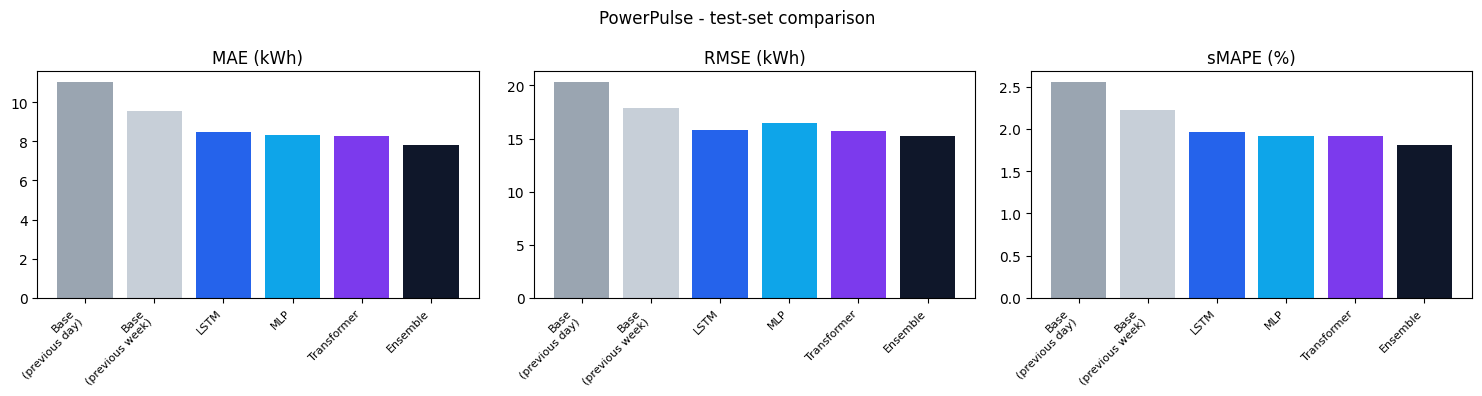

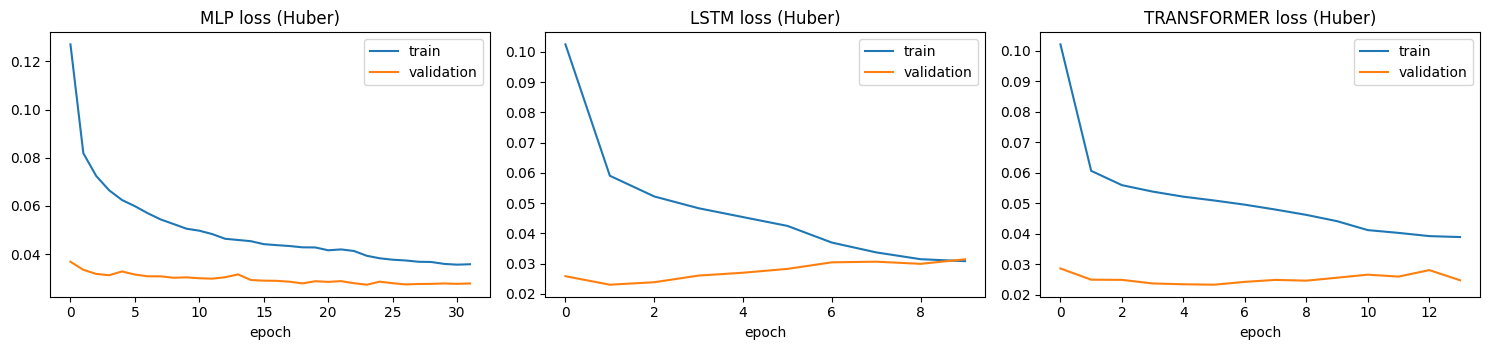

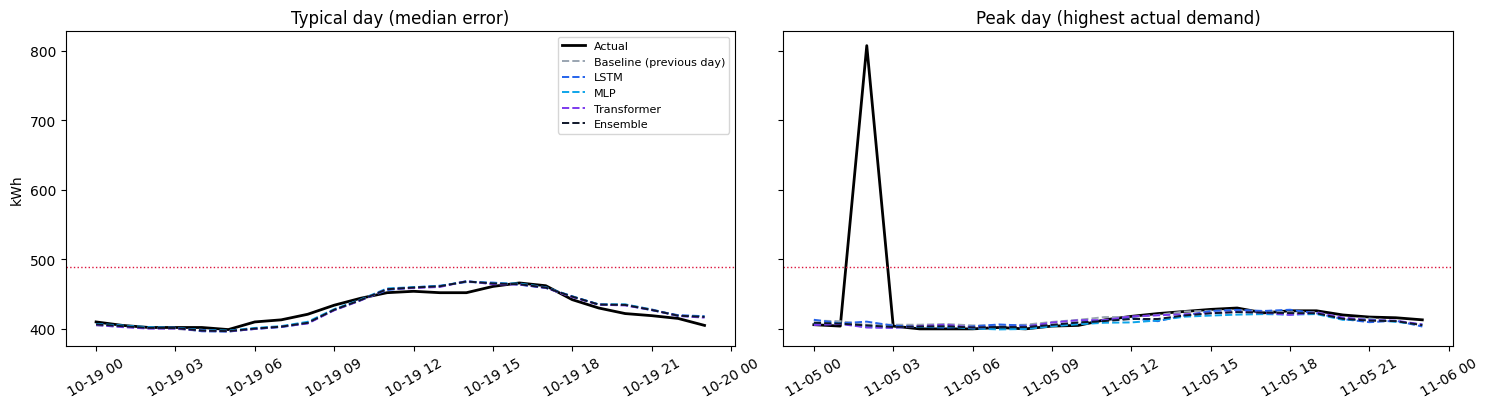

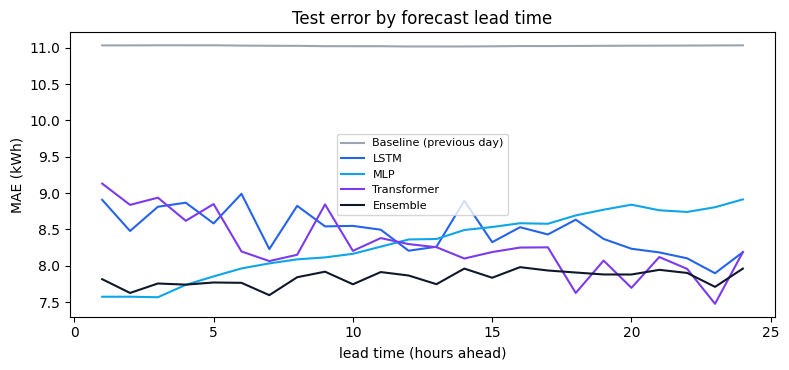

In [20]:
# ---- charts ----
colors = {"Baseline (previous day)": "#9aa5b1", "Baseline (previous week)": "#c7cfd8", "LSTM": "#2563eb",
          "MLP": "#0ea5e9", "Transformer": "#7c3aed", "Ensemble": "#0f172a"}
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axs, ["MAE", "RMSE", "sMAPE"]):
    vals = cmp_df[m]; ax.bar(range(len(vals)), vals, color=[colors[k] for k in vals.index])
    ax.set_xticks(range(len(vals))); ax.set_xticklabels([k.replace("Baseline ", "Base\n") for k in vals.index], rotation=45, ha="right", fontsize=8)
    ax.set_title(m + (" (kWh)" if m != "sMAPE" else " (%)"))
fig.suptitle("PowerPulse - test-set comparison"); fig.tight_layout(); savefig("02_model_comparison.png")

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6), sharey=False)
for ax, name in zip(axs, ("mlp", "lstm", "transformer")):
    ax.plot(HISTORY[name]["loss"], label="train"); ax.plot(HISTORY[name]["val_loss"], label="validation")
    ax.set_title(f"{name.upper()} loss (Huber)"); ax.set_xlabel("epoch"); ax.legend()
fig.tight_layout(); savefig("03_training_curves.png")

# representative days (forecast origin at midnight)
ts_test = frame.index[D["test"]["origins"]]
mid = np.where(ts_test.hour == 0)[0]
day_err = np.abs(ALL["test"][best_model][mid] - GT["test"][mid]).mean(axis=1)
picks = {"Typical day (median error)": mid[np.argsort(day_err)[len(mid) // 2]],
         "Peak day (highest actual demand)": mid[np.argmax(GT["test"][mid].max(axis=1))]}
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, (title, i) in zip(axs, picks.items()):
    t = frame.index[D["test"]["origins"][i]: D["test"]["origins"][i] + HORIZON]
    ax.plot(t, GT["test"][i], "k-", lw=2, label="Actual")
    for k in ["Baseline (previous day)", "LSTM", "MLP", "Transformer", "Ensemble"]:
        ax.plot(t, ALL["test"][k][i], "--", color=colors[k], lw=1.4, label=k)
    ax.axhline(PEAK_THR, color="crimson", ls=":", lw=1); ax.set_title(title); ax.tick_params(axis="x", rotation=30)
axs[0].set_ylabel("kWh"); axs[0].legend(fontsize=8); fig.tight_layout(); savefig("04_actual_vs_predicted.png")

mae_h = {k: np.abs(ALL["test"][k] - GT["test"]).mean(axis=0) for k in ["Baseline (previous day)", "LSTM", "MLP", "Transformer", "Ensemble"]}
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, v in mae_h.items(): ax.plot(range(1, HORIZON + 1), v, color=colors[k], label=k)
ax.set_xlabel("lead time (hours ahead)"); ax.set_ylabel("MAE (kWh)"); ax.set_title("Test error by forecast lead time"); ax.legend(fontsize=8)
fig.tight_layout(); savefig("05_error_by_lead_time.png")

## 10) Reliability: 80 % prediction interval + explainability profiles
Interval = per-lead-hour quantiles of the **validation** log-residuals of the selected model; its coverage is then checked on the test set.

In [21]:
sel_val, sel_test = ALL["val"][best_model], ALL["test"][best_model]
res_log = np.log1p(GT["val"]) - np.log1p(sel_val)
q10, q90 = np.quantile(res_log, 0.10, axis=0), np.quantile(res_log, 0.90, axis=0)
def interval(pred): return (np.expm1(np.log1p(pred) + q10), np.expm1(np.log1p(pred) + q90))
lo_t, hi_t = interval(sel_test)
coverage = float(np.mean((GT["test"] >= lo_t) & (GT["test"] <= hi_t)))
print(f"80% interval coverage on test: {coverage*100:.1f}%  (target ~80%)")

tr_frame = frame.iloc[:train_end]
dowh = tr_frame.groupby([tr_frame.index.dayofweek, tr_frame.index.hour])["load_kwh"]
profiles = {
    "peak_threshold_kwh": PEAK_THR, "peak_quantile": PEAK_QUANTILE,
    "dow_hour_mean": [[float(dowh.mean().get((d, h), np.nan)) for h in range(24)] for d in range(7)],
    "dow_hour_p90":  [[float(dowh.quantile(.9).get((d, h), np.nan)) for h in range(24)] for d in range(7)],
    "overall_mean_kwh": float(tr_frame["load_kwh"].mean()),
    "temp_load_corr_train": (float(tr_frame["load_kwh"].corr(tr_frame["air_temperature"])) if "air_temperature" in tr_frame else None),
    "note": "Computed on the TRAIN period only. Used by the backend for rule-based alert explanations.",
}
error_profile = {
    "selected_model": best_model,
    "interval_log_quantiles": {"q10": q10.tolist(), "q90": q90.tolist()},
    "interval_nominal": 0.80, "interval_test_coverage": coverage,
    "test_mae_by_lead_hour": {k: v.tolist() for k, v in mae_h.items()},
}
print("Peak threshold:", round(PEAK_THR, 1), "kWh | peak F1 (selected, test):", round(test_res[best_model]["peak_f1"], 3))

80% interval coverage on test: 83.1%  (target ~80%)
Peak threshold: 489.0 kWh | peak F1 (selected, test): 0.0


## 11) Export every artifact the backend needs (saved straight to the artifacts folder)

In [22]:
CFG_OUT = {"input_hours": INPUT_HOURS, "horizon": HORIZON, "weather_cols": WEATHER_USE,
           "cal_cols": pp.CAL_COLS, "feature_names": FEATURES, "model_input_keys": list(pp.MODEL_INPUT_KEYS),
           "normalizer": NORM, "peak_threshold_kwh": PEAK_THR,
           "ensemble_members": ["lstm", "mlp", "transformer"], "selected_model": best_model,
           "interval_log_quantiles": error_profile["interval_log_quantiles"]}
(CONFIG_PATH / "pipeline_config.json").write_text(json.dumps(CFG_OUT, indent=2))
(ARTIFACTS_PATH / "powerpulse_pipeline.py").write_text(PIPELINE_SRC)
(ARTIFACTS_PATH / "training_history.json").write_text(json.dumps(HISTORY, indent=2))
(ARTIFACTS_PATH / "best_hyperparameters.json").write_text(json.dumps(BEST_HP, indent=2))
pd.DataFrame(TUNING_ROWS).to_csv(ARTIFACTS_PATH / "tuning_log.csv", index=False)
(ARTIFACTS_PATH / "data_quality.json").write_text(json.dumps(data_quality, indent=2))
(DATA_OUT / "profiles.json").write_text(json.dumps(profiles, indent=2))
(DATA_OUT / "error_profile.json").write_text(json.dumps(error_profile, indent=2))

# full cleaned hourly data (history endpoint / backend inference input)
frame[["load_kwh"] + WEATHER_USE].to_csv(DATA_OUT / "hourly_building_data.csv")

# long-format test predictions for forecast origins at midnight (Model Comparison page)
rows = []
for i in mid:
    o = D["test"]["origins"][i]
    for h in range(HORIZON):
        r = {"origin": str(frame.index[o]), "timestamp": str(frame.index[o + h]), "lead_hour": h + 1,
             "actual": float(GT["test"][i, h])}
        for k, v in ALL["test"].items(): r[k] = float(v[i, h])
        r["selected_lower80"], r["selected_upper80"] = float(lo_t[i, h]), float(hi_t[i, h])
        rows.append(r)
pd.DataFrame(rows).to_csv(DATA_OUT / "test_predictions_daily.csv", index=False)

# genuine forecast beyond the latest observation (what the Overview page shows)
cand_o = np.arange(max(INPUT_HOURS, N - 72), N + 1)
lat = pp.build_inputs(frame, cand_o, CFG, NORM, with_target=False)
assert len(lat["origins"]), "No valid recent window - recent data has long gaps"
li = len(lat["origins"]) - 1
lat1 = {k: (v[li:li + 1] if isinstance(v, np.ndarray) else v) for k, v in lat.items()}
t0 = frame.index[0] + pd.Timedelta(hours=int(lat["origins"][li]))
lat_ts = pd.date_range(t0, periods=HORIZON, freq="h")
lat_pred = {lab: pp.denormalize(MODELS[nm].predict(pp.model_inputs(lat1), verbose=0), lat1["ref"], NORM)[0]
            for nm, lab in (("lstm", "LSTM"), ("mlp", "MLP"), ("transformer", "Transformer"))}
lat_pred["Ensemble"] = np.mean([lat_pred["LSTM"], lat_pred["MLP"], lat_pred["Transformer"]], axis=0)
lf = pd.DataFrame({"timestamp": lat_ts, **lat_pred})
lo_l, hi_l = interval(lat_pred[best_model][None, :])
lf["selected_lower80"], lf["selected_upper80"] = lo_l[0], hi_l[0]
lf["above_peak_threshold"] = lf[best_model] > PEAK_THR
lf.to_csv(DATA_OUT / "latest_forecast.csv", index=False)
print("Latest forecast origin:", t0, "| peak-risk hours:", int(lf["above_peak_threshold"].sum()))

metrics_payload = {
    "project": "PowerPulse", "dataset": data_quality["dataset"], "dataset_url": data_quality["dataset_url"],
    "building_id": BUILDING_ID, "site_id": SITE_ID, "input_hours": INPUT_HOURS, "horizon": HORIZON,
    "best_model": best_model, "selection_criterion": "lowest validation RMSE (test set never used for selection)",
    "peak_threshold_kwh": PEAK_THR,
    "models": {k: v for k, v in test_res.items()},
    "validation": {k: v for k, v in val_res.items()},
    "rmse_improvement_vs_previous_day_pct": imp,
    "interval_80_test_coverage": coverage,
    "split_sizes": {sp: int(len(D[sp]["origins"])) for sp in D},
    "model_files": {"lstm": "models/lstm.keras", "mlp": "models/mlp.keras", "transformer": "models/transformer.keras"},
    "config_file": "config/pipeline_config.json", "pipeline_module": "powerpulse_pipeline.py",
    "data_quality": data_quality,
}
(ARTIFACTS_PATH / "metrics.json").write_text(json.dumps(metrics_payload, indent=2))

Latest forecast origin: 2018-01-01 00:00:00 | peak-risk hours: 0


6103

## 12) Round-trip test — reload from disk exactly like the backend will
Loads the saved `.keras` files, the saved JSON config and the saved pipeline module, rebuilds inputs from the exported CSV, and checks that predictions match the in-memory models.

In [23]:
spec_path = ARTIFACTS_PATH / "powerpulse_pipeline.py"
spec = importlib.util.spec_from_file_location("pp_reloaded", spec_path); pp2 = importlib.util.module_from_spec(spec); spec.loader.exec_module(pp2)
cfg2 = json.loads((CONFIG_PATH / "pipeline_config.json").read_text())
cfg2_core = {"input_hours": cfg2["input_hours"], "horizon": cfg2["horizon"], "weather_cols": cfg2["weather_cols"]}
hourly = pd.read_csv(DATA_OUT / "hourly_building_data.csv", index_col=0, parse_dates=True)
frame2 = pp2.make_frame(hourly["load_kwh"], hourly, cfg2["weather_cols"])

chk_o = D["test"]["origins"][[0, len(D["test"]["origins"]) // 2, -1]]
d2 = pp2.build_inputs(frame2, chk_o, cfg2_core, cfg2["normalizer"], with_target=False)
worst = 0.0
for name in ("lstm", "mlp", "transformer"):
    m2 = keras.models.load_model(MODELS_PATH / f"{name}.keras")
    p2 = pp2.denormalize(m2.predict(pp2.model_inputs(d2), verbose=0), d2["ref"], cfg2["normalizer"])
    sel = np.searchsorted(D["test"]["origins"], chk_o)
    p1 = PRED["test"][{"lstm": "LSTM", "mlp": "MLP", "transformer": "Transformer"}[name]][sel]
    worst = max(worst, float(np.max(np.abs(p1 - p2))))
print(f"Max |difference| between in-memory and reloaded predictions: {worst:.6f} kWh")
assert worst < 0.5, "Round-trip mismatch - artifacts are not backend-safe"
print("Round-trip test passed: saved artifacts reproduce the training-time predictions.")

Max |difference| between in-memory and reloaded predictions: 0.000015 kWh
Round-trip test passed: saved artifacts reproduce the training-time predictions.


In [24]:
manifest = {
    "created_utc": pd.Timestamp.utcnow().strftime("%Y-%m-%dT%H:%M:%SZ"),
    "python": platform.python_version(), "tensorflow": tf.__version__, "keras": keras.__version__,
    "note": "Pin the SAME tensorflow/keras versions in the backend requirements.",
    "building_id": BUILDING_ID, "selected_model": best_model,
    "ensemble_members": ["lstm", "mlp", "transformer"],
    "latest_observation": data_quality["latest_observation"], "latest_forecast_origin": str(t0),
    "files": sorted(str(p.relative_to(ARTIFACTS_PATH)) for p in ARTIFACTS_PATH.rglob("*") if p.is_file() and p.suffix != ".zip"),
}
(ARTIFACTS_PATH / "artifact_manifest.json").write_text(json.dumps(manifest, indent=2))
print(json.dumps(manifest, indent=2))
print("\nTEST RESULTS (copy these into the PPT - they are the real numbers):")
display(cmp_df.round(3))

{
  "created_utc": "2026-10-16T19:31:27Z",
  "python": "3.13.15",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "note": "Pin the SAME tensorflow/keras versions in the backend requirements.",
  "building_id": "Hog_office_Rolando",
  "selected_model": "Ensemble",
  "ensemble_members": [
    "lstm",
    "mlp",
    "transformer"
  ],
  "latest_observation": "2017-12-31 23:00:00",
  "latest_forecast_origin": "2018-01-01 00:00:00",
  "files": [
    "__pycache__/powerpulse_pipeline.cpython-313.pyc",
    "best_hyperparameters.json",
    "config/pipeline_config.json",
    "data/error_profile.json",
    "data/hourly_building_data.csv",
    "data/latest_forecast.csv",
    "data/profiles.json",
    "data/test_predictions_daily.csv",
    "data_quality.json",
    "figures/01_demand_timeline.png",
    "figures/02_model_comparison.png",
    "figures/03_training_curves.png",
    "figures/04_actual_vs_predicted.png",
    "figures/05_error_by_lead_time.png",
    "metrics.json",
    "models/lstm.keras"

,val_RMSE,MAE,RMSE,sMAPE,CVRMSE,NMBE,peak_precision,peak_recall,peak_f1
Baseline (previous day),19.251,11.028,20.307,2.555,4.784,0.066,0.0,0.0,0.0
Baseline (previous week),15.988,9.546,17.885,2.228,4.213,0.240,0.0,0.0,0.0
LSTM,11.653,8.481,15.840,1.968,3.731,0.286,0.0,0.0,0.0
MLP,11.528,8.307,16.497,1.914,3.886,0.198,0.0,0.0,0.0
Transformer,11.711,8.279,15.688,1.920,3.695,0.328,0.0,0.0,0.0
Ensemble,11.057,7.832,15.272,1.813,3.598,0.271,0.0,0.0,0.0


## 13) Package & deliver

In [25]:
import os
from google.colab import files

# 1) Zip every artifact and keep a copy on Drive
zip_on_drive = Path(shutil.make_archive(str(BASE_DRIVE / "powerpulse_artifacts"), "zip", ARTIFACTS_PATH))
print("Zip saved to Drive:", zip_on_drive, f"({zip_on_drive.stat().st_size/1e6:.1f} MB)")
print("Unzipped artifacts also live permanently in:", ARTIFACTS_PATH)
for p in sorted(ARTIFACTS_PATH.rglob("*")):
    if p.is_file():
        print(f"  {str(p.relative_to(ARTIFACTS_PATH)):45s} {p.stat().st_size/1e3:10.1f} KB")

# 2) Download to your computer (served from a local copy so it is independent of Drive)
local_zip = "/content/powerpulse_artifacts.zip"
shutil.copy(zip_on_drive, local_zip)
files.download(local_zip)

# 3) Make sure Drive has finished writing everything (set False if you want to keep working in this runtime)
FLUSH_DRIVE_AT_END = True
if FLUSH_DRIVE_AT_END:
    drive.flush_and_unmount()
    print("Drive flushed & unmounted - all files are safely stored in MyDrive/PowerPulse/")

Zip saved to Drive: /content/drive/MyDrive/PowerPulse/powerpulse_artifacts.zip (9.7 MB)
Unzipped artifacts also live permanently in: /content/drive/MyDrive/PowerPulse/artifacts
  __pycache__/powerpulse_pipeline.cpython-313.pyc       13.2 KB
  artifact_manifest.json                               1.2 KB
  best_hyperparameters.json                            0.3 KB
  config/pipeline_config.json                          2.9 KB
  data/error_profile.json                              4.7 KB
  data/hourly_building_data.csv                      891.7 KB
  data/latest_forecast.csv                             3.4 KB
  data/profiles.json                                   6.9 KB
  data/test_predictions_daily.csv                    447.1 KB
  data_quality.json                                    1.4 KB
  figures/01_demand_timeline.png                      97.2 KB
  figures/02_model_comparison.png                     57.8 KB
  figures/03_training_curves.png                      82.8 KB
  figures/04_ac

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Drive flushed & unmounted - all files are safely stored in MyDrive/PowerPulse/
